# Practical 3: Exploratory data analysis

## Aim
Tenure percentages, cross-tabulation, age summary, histogram, bar charts and median score on the Teaching Ratings data. The original evals.csv file was not available, so the equivalent Teaching Ratings data is used.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
prof = pd.read_csv("TeachingRatings.csv")

In [3]:
prof.info()
print(prof.describe().round(4))

<class 'pandas.DataFrame'>
RangeIndex: 463 entries, 0 to 462
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   rownames     463 non-null    int64  
 1   minority     463 non-null    str    
 2   age          463 non-null    int64  
 3   gender       463 non-null    str    
 4   credits      463 non-null    str    
 5   beauty       463 non-null    float64
 6   eval         463 non-null    float64
 7   division     463 non-null    str    
 8   native       463 non-null    str    
 9   tenure       463 non-null    str    
 10  students     463 non-null    int64  
 11  allstudents  463 non-null    int64  
 12  prof         463 non-null    int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 47.2 KB
       rownames       age    beauty      eval  students  allstudents      prof
count  463.0000  463.0000  463.0000  463.0000  463.0000     463.0000  463.0000
mean   232.0000   48.3650    0.0000    3.9983   36.6242    

In [4]:
minority = prof[prof["minority"] == "yes"]
pct = (minority["tenure"] == "yes").mean() * 100
print("\nMinority instructors with tenure: %.2f%%" % pct)
print("All other instructors with tenure: %.2f%%" % ((prof[prof["minority"] == "no"]["tenure"] == "yes").mean() * 100))


Minority instructors with tenure: 84.38%
All other instructors with tenure: 76.94%


In [5]:
print("\nMinority vs tenure:")
print(pd.crosstab(prof["minority"], prof["tenure"]))


Minority vs tenure:
tenure    no  yes
minority         
no        92  307
yes       10   54


In [6]:
print("\nAge by tenure status:")
print(prof.groupby("tenure")["age"].agg(["mean", "std"]).round(4))


Age by tenure status:
           mean      std
tenure                  
no      50.1863   6.9464
yes     47.8504  10.4201


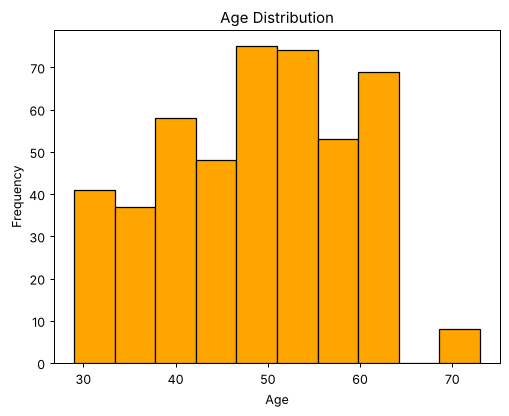

In [7]:
plt.hist(prof["age"], bins=10, color="orange", edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

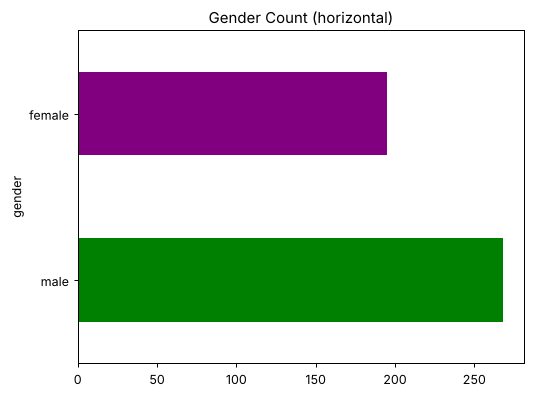

In [8]:
counts = prof["gender"].value_counts()
counts.plot(kind="barh", color=["green", "purple"])
plt.title("Gender Count (horizontal)")
plt.show()


Gender counts:
gender
male      268
female    195
Name: count, dtype: int64


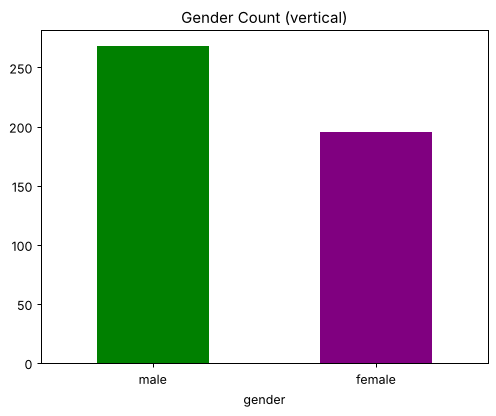

In [9]:
counts.plot(kind="bar", color=["green", "purple"], rot=0)
plt.title("Gender Count (vertical)")
plt.show()
print("\nGender counts:")
print(counts)

In [10]:
print("\nMedian evaluation of tenured instructors:", prof[prof["tenure"] == "yes"]["eval"].median())


Median evaluation of tenured instructors: 4.0


In [11]:
ages = prof.groupby("tenure")["age"].mean()
older = "tenured" if ages["yes"] > ages["no"] else "untenured"
share = "higher" if pct > (prof[prof["minority"] == "no"]["tenure"] == "yes").mean() * 100 else "lower"
print("\nResult: %s instructors are older on average, and the tenure share of minority" % older)
print("instructors (%.2f%%) is %s than that of the rest." % (pct, share))


Result: untenured instructors are older on average, and the tenure share of minority
instructors (84.38%) is higher than that of the rest.
